# Fields of a sphere in a plane wave

This notebook computes the fields near a sphere in a plane wave: the electric and the magnetic fields in optics, and the pressure and the velocity in acoustics.
The fields are the classical Mie series with the coefficients $a_n$, $b_n$, $c_n$ and $d_n$ from `mielib`:
the series of Bohren & Huffman in optics, and the same series for the pressure in acoustics.
The [theory note](https://github.com/toftul/mielib/blob/main/docs/theory/mielib_theory.pdf) gives them in the sections
"Real harmonics of Bohren and Huffman" and "Acoustic Mie problem".
The positions are in units of the radius $a$.
The figures use the style file `phys-plots.mplstyle` and the helpers in `figure_style.py`, which are next to this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sp

from mielib import acoustics, coordinates, optics, special, vsh
from figure_style import use_paper_style, figure, letter, edges, signed_map

use_paper_style()

PosixPath('/home/ivan/Documents/GitHub/mielib/examples/phys-plots.mplstyle')

## Optics

The sphere of `cross_sections.ipynb`: the radius $a = 100$ nm and the permittivity $\varepsilon_p = 16 + 0.3i$ in vacuum.
The wavelength is at the maximum of the magnetic dipole scattering, row $j = 1$ of `q.sca_m`.

In [2]:
nm = 1e-9
a = 100 * nm
eps_p, mu_p = 16 + 0.3j, 1
eps_h, mu_h = 1, 1
eps_rel, mu_rel = eps_p / eps_h, mu_p / mu_h

wavelength = np.linspace(500, 1100, 1201) * nm          # in vacuum
k = np.sqrt(eps_h * mu_h) * 2 * np.pi / wavelength     # in the host
q = optics.cross_sections(k, a, eps_rel, mu_rel)

i = np.argmax(q.sca_m[1])
ka = k[i] * a
print(f'wavelength = {wavelength[i] / nm:.1f} nm, ka = {ka:.3f}')

wavelength = 830.5 nm, ka = 0.757


The incident wave is $\mathbf{E} = E_0\hat{\mathbf{x}}\, e^{ikz}$ and $\mathbf{H} = H_0\hat{\mathbf{y}}\, e^{ikz}$ with $H_0 = kE_0/(\omega\mu)$.
With $E_n = i^n(2n+1)/[n(n+1)]$, the fields are (Bohren & Huffman, Ch. 4)
$$
\begin{aligned}
\frac{\mathbf{E}_{\rm inc}}{E_0} &= \sum_n E_n\left(\mathbf{M}^{(1)}_{o1n} - i\mathbf{N}^{(1)}_{e1n}\right), &
\frac{\mathbf{H}_{\rm inc}}{H_0} &= -\sum_n E_n\left(\mathbf{M}^{(1)}_{e1n} + i\mathbf{N}^{(1)}_{o1n}\right), \\
\frac{\mathbf{E}_{\rm sc}}{E_0} &= \sum_n E_n\left(i a_n\mathbf{N}^{(3)}_{e1n} - b_n\mathbf{M}^{(3)}_{o1n}\right), &
\frac{\mathbf{H}_{\rm sc}}{H_0} &= \sum_n E_n\left(i b_n\mathbf{N}^{(3)}_{o1n} + a_n\mathbf{M}^{(3)}_{e1n}\right), \\
\frac{\mathbf{E}_{\rm in}}{E_0} &= \sum_n E_n\left(c_n\mathbf{M}^{(1)}_{o1n} - i d_n\mathbf{N}^{(1)}_{e1n}\right), &
\frac{\mathbf{H}_{\rm in}}{H_0} &= -\frac{m}{\mu_{\rm rel}}\sum_n E_n\left(d_n\mathbf{M}^{(1)}_{e1n} + i c_n\mathbf{N}^{(1)}_{o1n}\right).
\end{aligned}
$$
The real harmonics are `vsh.M_real` and `vsh.N_real` with $m = 1$, and the superscripts (1) and (3) are the radial functions $j_n$ and $h^{(1)}_n$.
Outside, the harmonics have $\rho = kr$. Inside, they have $\rho = k_p r = mkr$ with $m = \sqrt{\varepsilon_{\rm rel}\mu_{\rm rel}}$.
The coefficients are `optics.mie_a`, `optics.mie_b`, `optics.mie_c` and `optics.mie_d`.

In [3]:
def bh_harmonics(n, rho, theta, phi, superscript):
    # M_o1n, M_e1n, N_o1n and N_e1n of Bohren & Huffman
    return [W(n, 1, rho, theta, phi, superscript=superscript, parity=parity)
            for W, parity in [(vsh.M_real, 'odd'), (vsh.M_real, 'even'), (vsh.N_real, 'odd'), (vsh.N_real, 'even')]]


def optical_fields(x, y, z, ka, eps_rel, mu_rel, jmax):
    # E/E0 and H/H0 in Cartesian components at the points (x, y, z) in units of a
    x, y, z = np.broadcast_arrays(x, y, z)
    r, theta, phi = coordinates.cart2sph(x, y, z)
    out, ins = r >= 1, r < 1
    m = np.sqrt(eps_rel + 0j) * np.sqrt(mu_rel + 0j)       # k_p = m k

    E = np.zeros((3,) + r.shape, dtype=complex)
    H = np.zeros((3,) + r.shape, dtype=complex)
    for n in range(1, jmax + 1):
        En = 1j**n * (2 * n + 1) / (n * (n + 1))
        an, bn, cn, dn = (f(n, ka, eps_rel, mu_rel) for f in [optics.mie_a, optics.mie_b, optics.mie_c, optics.mie_d])

        # outside: the incident and the scattered fields
        Mo1, Me1, No1, Ne1 = bh_harmonics(n, ka * r[out], theta[out], phi[out], superscript=1)
        Mo3, Me3, No3, Ne3 = bh_harmonics(n, ka * r[out], theta[out], phi[out], superscript=3)
        E[:, out] += En * (Mo1 - 1j * Ne1 + 1j * an * Ne3 - bn * Mo3)
        H[:, out] += En * (-Me1 - 1j * No1 + 1j * bn * No3 + an * Me3)

        # inside
        Mo1, Me1, No1, Ne1 = bh_harmonics(n, m * ka * r[ins], theta[ins], phi[ins], superscript=1)
        E[:, ins] += En * (cn * Mo1 - 1j * dn * Ne1)
        H[:, ins] += -m / mu_rel * En * (dn * Me1 + 1j * cn * No1)

    return coordinates.vector_sph2cart(E, theta, phi), coordinates.vector_sph2cart(H, theta, phi)

All the sums stop at one $j_{\max}$.
The incident series converges only for $kr$ below about $j_{\max}$, so $j_{\max}$ is `special.wiscombe_jmax` at the corners of the plot, $r = 3\sqrt{2}\,a$.

**Checks.** (1) Without the sphere, $\varepsilon_{\rm rel} = \mu_{\rm rel} = 1$, so $a_n = b_n = 0$ and $c_n = d_n = 1$, and the sums must give the incident wave everywhere in the plot.
(2) The tangential components of $\mathbf{E}$ and $\mathbf{H}$ and the normal components of $\varepsilon\mathbf{E}$ and $\mu\mathbf{H}$ are continuous at $r = a$.

In [4]:
jmax = special.wiscombe_jmax(ka * 3 * np.sqrt(2))
print(f'jmax = {jmax}')

X, Z = np.meshgrid(np.linspace(-3, 3, 61), np.linspace(-3, 3, 61))
E, H = optical_fields(X, 0, Z, ka, 1, 1, jmax)
wave, zero = np.exp(1j * ka * Z), np.zeros(Z.shape)
print('without the sphere, the largest error in')
print(f'  E:  {np.max(np.abs(E - [wave, zero, zero])):.1e}')
print(f'  H:  {np.max(np.abs(H - [zero, wave, zero])):.1e}')

theta, phi = np.meshgrid(np.linspace(0.1, 3.0, 7), np.linspace(0.2, 6.0, 7))
sides = []
for r in [1 - 1e-12, 1 + 1e-12]:
    E, H = optical_fields(*coordinates.sph2cart(r, theta, phi), ka, eps_rel, mu_rel, jmax)
    sides.append((coordinates.vector_cart2sph(E, theta, phi), coordinates.vector_cart2sph(H, theta, phi)))
(E_in, H_in), (E_out, H_out) = sides

print('at r = a, the largest jump in')
print(f'  tangential E:  {np.max(np.abs(E_in[1:] - E_out[1:])):.1e}')
print(f'  tangential H:  {np.max(np.abs(H_in[1:] - H_out[1:])):.1e}')
print(f'  normal eps E:  {np.max(np.abs(eps_rel * E_in[0] - E_out[0])):.1e}')
print(f'  normal mu H:   {np.max(np.abs(mu_rel * H_in[0] - H_out[0])):.1e}')

jmax = 11


without the sphere, the largest error in
  E:  3.0e-06
  H:  8.4e-07
at r = a, the largest jump in
  tangential E:  1.0e-11
  tangential H:  1.9e-11
  normal eps E:  1.7e-11
  normal mu H:   3.4e-11


**Figure 1.** The fields at the magnetic dipole resonance.
(A) The electric field $|\mathbf{E}|/E_0$ in the plane $y = 0$.
(B) The magnetic field $|\mathbf{H}|/H_0$ in the plane $x = 0$.
The incident $\mathbf{E}$ is along $x$, and the mirror symmetries of the problem keep $\mathbf{E}$ in the plane $y = 0$ and $\mathbf{H}$ in the plane $x = 0$.
The lines show the instantaneous fields $\mathrm{Re}[\mathbf{E}\, e^{-i\omega t}]$ and $\mathrm{Re}[\mathbf{H}\, e^{-i\omega t}]$ at $\omega t = \pi/4$.
The dashed circle is the surface of the sphere.
The electric field circulates in a loop inside the sphere, and the magnetic field goes through the loop along $y$, as for a magnetic dipole along $y$.
At the centre, $|\mathbf{H}| \approx 20 H_0$.

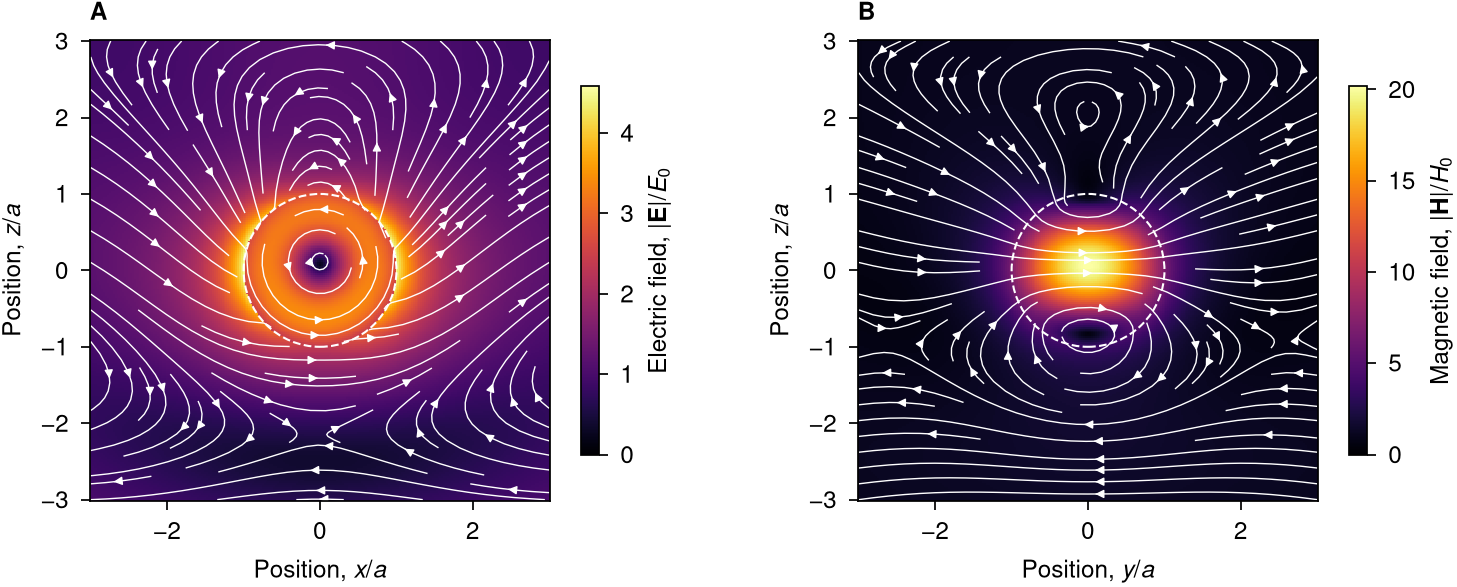

In [5]:
u = np.linspace(-3, 3, 241)                     # position in units of a
U, V = np.meshgrid(u, u)
E, _ = optical_fields(U, 0, V, ka, eps_rel, mu_rel, jmax)
_, H = optical_fields(0, U, V, ka, eps_rel, mu_rel, jmax)
wt = np.pi / 4


def vector_map(ax, u, F, i, wt, label):
    # |F| and the lines of Re[F exp(-iωt)] in a plane; F[i] is along the horizontal axis and F[2] along z
    magnitude = np.sqrt(np.sum(np.abs(F)**2, axis=0))
    mesh = ax.pcolormesh(edges(u), edges(u), magnitude, vmin=0, shading='flat', rasterized=True)
    snapshot = np.real(F * np.exp(-1j * wt))
    ax.streamplot(u, u, snapshot[i], snapshot[2], color='w', linewidth=0.4, arrowsize=0.5)
    bar = ax.figure.colorbar(mesh, ax=ax, shrink=0.8, label=label)
    bar.outline.set_linewidth(0.5)


fig, (ax1, ax2) = figure('double', cols=2)
vector_map(ax1, u, E, 0, wt, r'Electric field, $|\mathbf{E}|/E_0$')
vector_map(ax2, u, H, 1, wt, r'Magnetic field, $|\mathbf{H}|/H_0$')

for ax, horizontal, name in zip([ax1, ax2], 'xy', 'AB'):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='w', ls='--', lw=0.6))
    ax.set_aspect('equal')
    ax.set_xlabel(rf'Position, ${horizontal}/a$')
    ax.set_ylabel(r'Position, $z/a$')
    letter(ax, name)

plt.show()

## Acoustics

The fluid sphere of `cross_sections.ipynb`, with the density $\rho_{\rm rel} = 3 + 0.1i$ and the compressibility $\beta_{\rm rel} = 2$ relative to the host.
The size parameter is at the maximum of the dipole scattering, row $j = 1$ of `q.sca_j`.

In [6]:
rho_rel, beta_rel = 3 + 0.1j, 2

a = 1
k = np.linspace(0.01, 5, 2000)
q = acoustics.cross_sections(k, a, rho_rel, beta_rel)

ka = k[np.argmax(q.sca_j[1])] * a
print(f'ka = {ka:.3f}')

ka = 1.528


The incident wave is $p = p_0 e^{ikz}$.
With $p_n = i^n(2n+1)$, the pressures are
$$
\frac{p_{\rm inc}}{p_0} = \sum_n p_n\, j_n(kr)\, P_n(\cos\theta), \qquad
\frac{p_{\rm sc}}{p_0} = \sum_n p_n\, a_n\, h^{(1)}_n(kr)\, P_n(\cos\theta), \qquad
\frac{p_{\rm in}}{p_0} = \sum_n p_n\, c_n\, j_n(k_p r)\, P_n(\cos\theta),
$$
with $k_p = k\sqrt{\rho_{\rm rel}\beta_{\rm rel}}$ and the coefficients `acoustics.mie_a` and `acoustics.mie_c`.
The velocity is $\mathbf{v} = \nabla p/(i\omega\rho)$, with $\rho_p$ inside.
In the units $p_0/(\rho c)$ of the host, where the incident wave has $\rho c|\mathbf{v}| = p_0$,
$$
\frac{\rho c\, \mathbf{v}}{p_0} = -\frac{i\, \nabla p}{k p_0} \ \text{outside}, \qquad
\frac{\rho c\, \mathbf{v}}{p_0} = -\frac{i\, \nabla p}{\rho_{\rm rel}\, k p_0} \ \text{inside},
$$
and each term of the series has the gradient
$\nabla\left[z_n(\kappa r)\, P_n(\cos\theta)\right] = \kappa\, z_n'(\kappa r)\, P_n\, \hat{\mathbf{r}} + \frac{z_n(\kappa r)}{r}\frac{dP_n}{d\theta}\, \hat{\boldsymbol{\theta}}$,
with $\kappa = k$ outside and $\kappa = k_p$ inside.

In [7]:
def acoustic_fields(x, y, z, ka, rho_rel, beta_rel, jmax):
    # p/p0 and ρc v/p0 in Cartesian components at the points (x, y, z) in units of a
    x, y, z = np.broadcast_arrays(x, y, z)
    r, theta, phi = coordinates.cart2sph(x, y, z)
    # to prevent division by zero at the centre
    r = np.maximum(r, 1e-15)
    out, ins = r >= 1, r < 1
    n_rel = np.sqrt(rho_rel + 0j) * np.sqrt(beta_rel + 0j)     # k_p = n_rel k

    p = np.zeros(r.shape, dtype=complex)
    v = np.zeros((3,) + r.shape, dtype=complex)                # (v_r, v_θ, v_φ)
    for n in range(jmax + 1):
        pn = 1j**n * (2 * n + 1)
        an, cn = acoustics.mie_a(n, ka, rho_rel, beta_rel), acoustics.mie_c(n, ka, rho_rel, beta_rel)
        P, dP = sp.legendre_p(n, np.cos(theta), diff_n=1)
        dP = -np.sin(theta) * dP                               # d P_n(cos θ) / dθ

        # outside: the incident and the scattered pressures
        s = ka * r[out]
        zn = special.spherical_jn(n, s) + an * special.spherical_h1(n, s)
        dzn = special.spherical_jn(n, s, derivative=1) + an * special.spherical_h1(n, s, derivative=1)
        p[out] += pn * zn * P[out]
        v[0, out] += -1j * pn * dzn * P[out]
        v[1, out] += -1j * pn * zn / s * dP[out]

        # inside
        s = n_rel * ka * r[ins]
        zn, dzn = cn * special.spherical_jn(n, s), cn * special.spherical_jn(n, s, derivative=1)
        p[ins] += pn * zn * P[ins]
        v[0, ins] += -1j * n_rel / rho_rel * pn * dzn * P[ins]
        v[1, ins] += -1j * n_rel / rho_rel * pn * zn / s * dP[ins]

    return p, coordinates.vector_sph2cart(v, theta, phi)

**Checks.** (1) Without the sphere, $\rho_{\rm rel} = \beta_{\rm rel} = 1$, so $a_n = 0$ and $c_n = 1$, and the sums must give the incident wave everywhere in the plot.
(2) The pressure and the normal velocity are continuous at $r = a$.

In [8]:
jmax = special.wiscombe_jmax(ka * 3 * np.sqrt(2))
print(f'jmax = {jmax}')

p, v = acoustic_fields(X, 0, Z, ka, 1, 1, jmax)
wave, zero = np.exp(1j * ka * Z), np.zeros(Z.shape)
print('without the sphere, the largest error in')
print(f'  p:  {np.max(np.abs(p - wave)):.1e}')
print(f'  v:  {np.max(np.abs(v - [zero, zero, wave])):.1e}')

sides = []
for r in [1 - 1e-12, 1 + 1e-12]:
    p, v = acoustic_fields(*coordinates.sph2cart(r, theta, phi), ka, rho_rel, beta_rel, jmax)
    sides.append((p, coordinates.vector_cart2sph(v, theta, phi)))
(p_in, v_in), (p_out, v_out) = sides

print('at r = a, the largest jump in')
print(f'  pressure:         {np.max(np.abs(p_in - p_out)):.1e}')
print(f'  normal velocity:  {np.max(np.abs(v_in[0] - v_out[0])):.1e}')

jmax = 16
without the sphere, the largest error in
  p:  1.2e-06
  v:  3.0e-06
at r = a, the largest jump in
  pressure:         1.6e-11
  normal velocity:  5.7e-12


**Figure 2.** The fields at the dipole resonance in the plane $y = 0$.
(A) The instantaneous pressure $\mathrm{Re}[p\, e^{-i\omega t}]/p_0$ at $\omega t = \pi/4$. The dotted lines are $p = 0$.
(B) The velocity $\rho c|\mathbf{v}|/p_0$, and the lines of $\mathrm{Re}[\mathbf{v}\, e^{-i\omega t}]$ at the same time.
The problem is symmetric about the $z$ axis, so $\mathbf{v}$ is in the plane.
The dashed circle is the surface of the sphere.
Inside the sphere the pressure has opposite signs near the top and the bottom, as for a dipole along $z$,
and the velocity is largest at the centre, $\rho c|\mathbf{v}| \approx 3 p_0$.

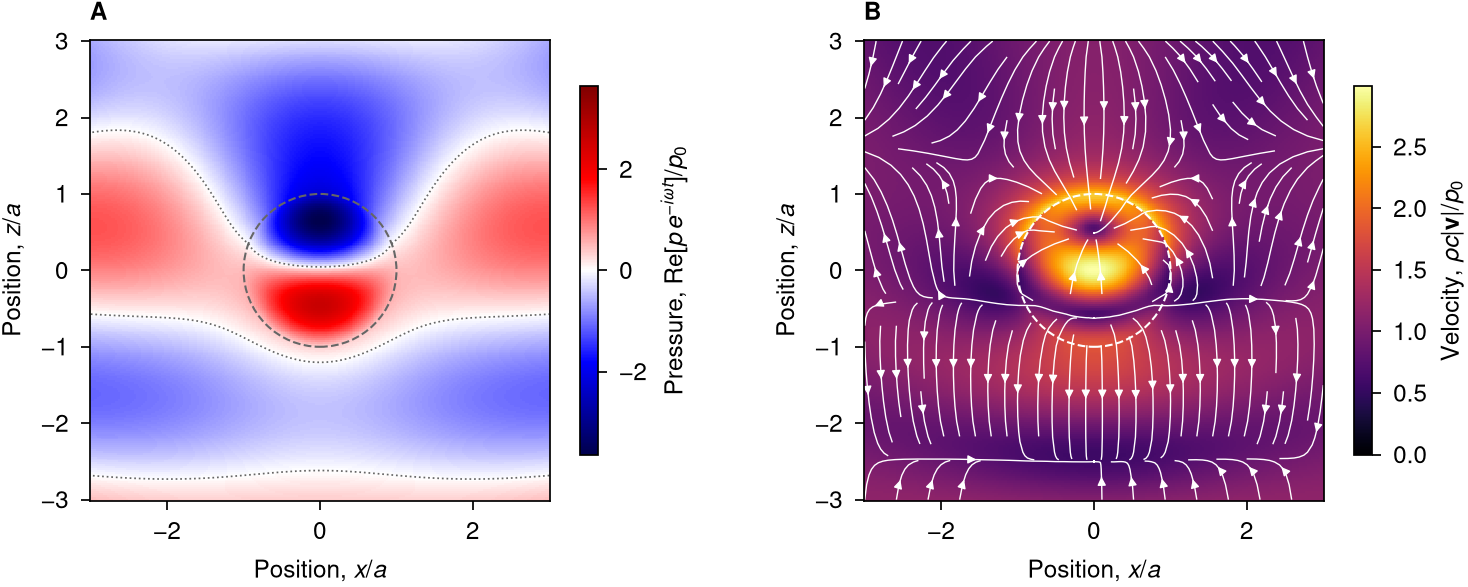

In [9]:
p, v = acoustic_fields(U, 0, V, ka, rho_rel, beta_rel, jmax)

fig, (ax1, ax2) = figure('double', cols=2)
mesh = signed_map(ax1, u, u, np.real(p * np.exp(-1j * wt)))
bar = fig.colorbar(mesh, ax=ax1, shrink=0.8, label=r'Pressure, $\mathrm{Re}[p\, e^{-i\omega t}]/p_0$')
bar.outline.set_linewidth(0.5)
vector_map(ax2, u, v, 0, wt, r'Velocity, $\rho c|\mathbf{v}|/p_0$')

for ax, color, name in zip([ax1, ax2], ['0.4', 'w'], 'AB'):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=color, ls='--', lw=0.6))
    ax.set_aspect('equal')
    ax.set_xlabel(r'Position, $x/a$')
    ax.set_ylabel(r'Position, $z/a$')
    letter(ax, name)

plt.show()